# 03 — Model Explainability with SHAP

**Project:** Credit Card Fraud Detection  
**Goal:** Understand *why* the model predicts a transaction as fraud

**What we will do:**
- Load the best model from Notebook 02
- Compute SHAP values
- Global interpretability (which features matter most)
- Local interpretability (explanation for individual fraud cases)
- Dependence plots & interaction insights

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

import shap
from sklearn.metrics import classification_report

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Initialize JS for interactive plots (works in Jupyter)
shap.initjs()

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load processed data
X_train = pd.read_parquet('../data/processed/X_train.parquet')
X_test  = pd.read_parquet('../data/processed/X_test.parquet')
y_train = pd.read_parquet('../data/processed/y_train.parquet')['Class']
y_test  = pd.read_parquet('../data/processed/y_test.parquet')['Class']

# Load the best model saved in Notebook 02
best_model = joblib.load('../models/best_fraud_model.pkl')

print("Data and model loaded successfully!")
print(f"Model type: {type(best_model).__name__}")
print(f"X_test shape: {X_test.shape}")

Data and model loaded successfully!
Model type: LGBMClassifier
X_test shape: (56962, 30)


In [3]:
y_pred = best_model.predict(X_test)
print("Classification Report on Test Set:")
print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

Classification Report on Test Set:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     56864
       Fraud       0.06      0.85      0.12        98

    accuracy                           0.98     56962
   macro avg       0.53      0.91      0.55     56962
weighted avg       1.00      0.98      0.99     56962



In [4]:
# For tree-based models (XGBoost / LightGBM / RandomForest) → TreeExplainer is fast & exact
explainer = shap.TreeExplainer(best_model)

# Calculate SHAP values on the test set
# (Using a sample is recommended if the dataset is very large)
sample_size = 2000
X_test_sample = X_test.sample(sample_size, random_state=42)
y_test_sample = y_test.loc[X_test_sample.index]

print("Calculating SHAP values... (this may take 1-3 minutes)")
shap_values = explainer.shap_values(X_test_sample)

print("SHAP values calculated successfully!")
print(f"SHAP values shape: {np.array(shap_values).shape}")

Calculating SHAP values... (this may take 1-3 minutes)
SHAP values calculated successfully!
SHAP values shape: (2000, 30)


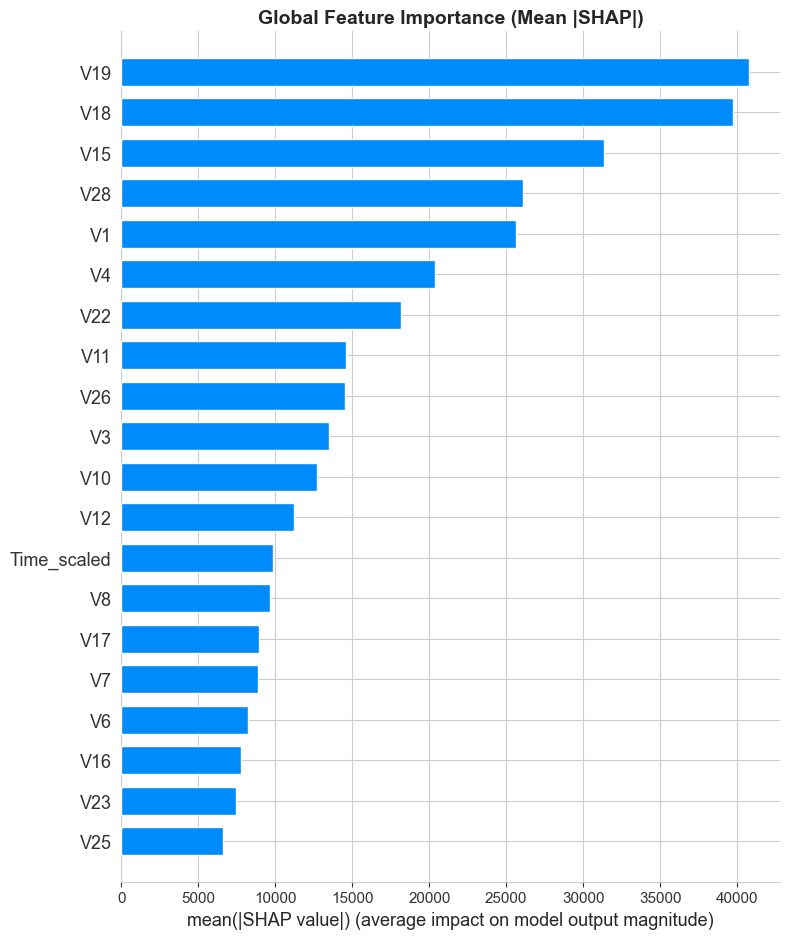

In [5]:
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_sample, plot_type="bar", show=False)
plt.title("Global Feature Importance (Mean |SHAP|)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

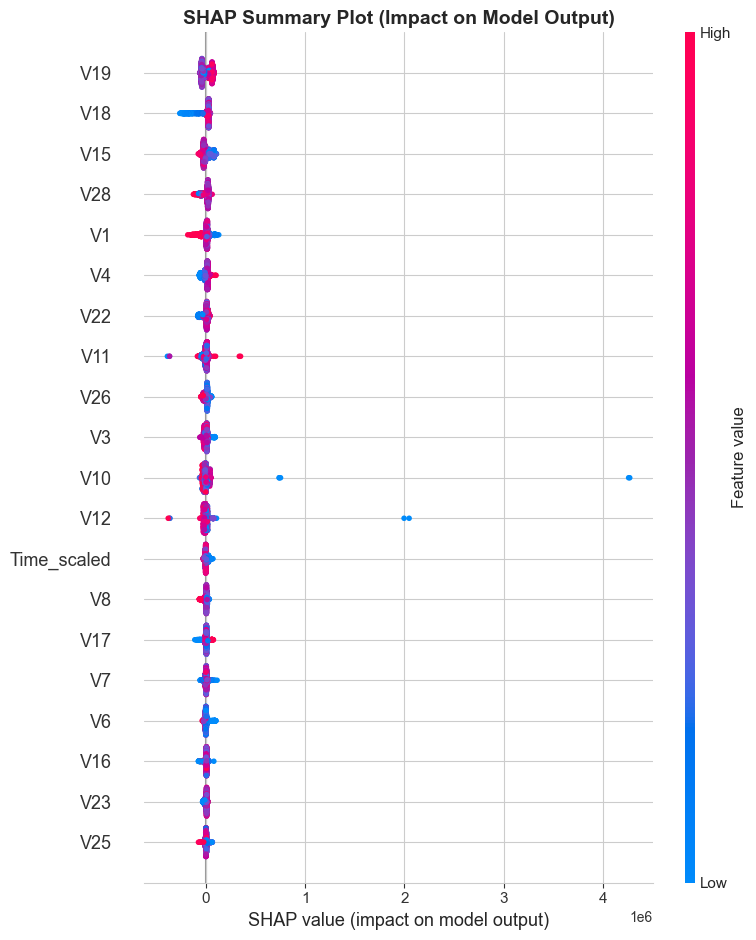

In [6]:
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title("SHAP Summary Plot (Impact on Model Output)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [7]:
# Get mean absolute SHAP values
if isinstance(shap_values, list):  # for some models shap_values is a list
    mean_shap = np.abs(shap_values[1]).mean(axis=0)
else:
    mean_shap = np.abs(shap_values).mean(axis=0)

feature_importance = pd.DataFrame({
    'Feature': X_test_sample.columns,
    'Mean_|SHAP|': mean_shap
}).sort_values('Mean_|SHAP|', ascending=False)

print("Top 15 Most Important Features:")
display(feature_importance.head(15))

Top 15 Most Important Features:


,Feature,Mean_|SHAP|
18,V19,40742.715182
17,V18,39742.207034
14,V15,31359.495840
27,V28,26083.228886
0,V1,25603.414487
3,V4,20396.152116
21,V22,18164.585915
10,V11,14603.665375
25,V26,14518.555861
2,V3,13495.184986


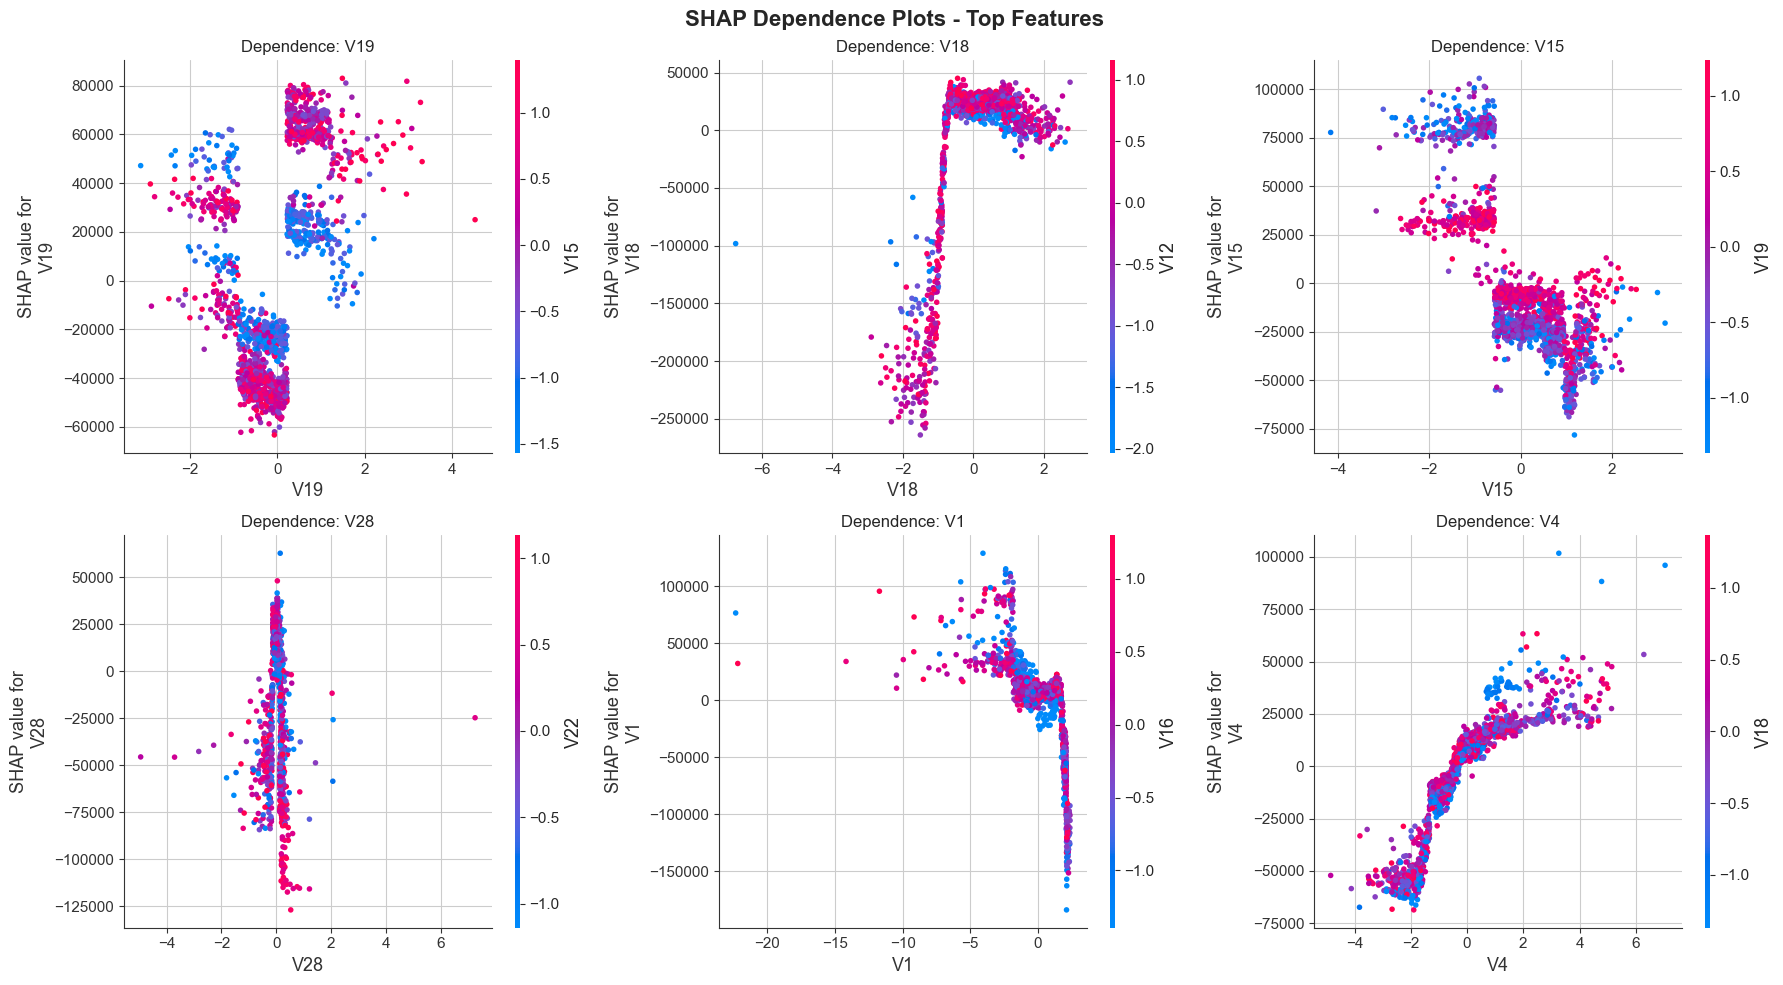

In [8]:
top_features = feature_importance['Feature'].head(6).tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    shap.dependence_plot(
        feature, 
        shap_values, 
        X_test_sample, 
        ax=axes[i], 
        show=False
    )
    axes[i].set_title(f"Dependence: {feature}", fontsize=12)

plt.suptitle("SHAP Dependence Plots - Top Features", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

Explaining Fraud Case (index: 153835)
True Label: 1
Predicted Probability of Fraud: 1.0000


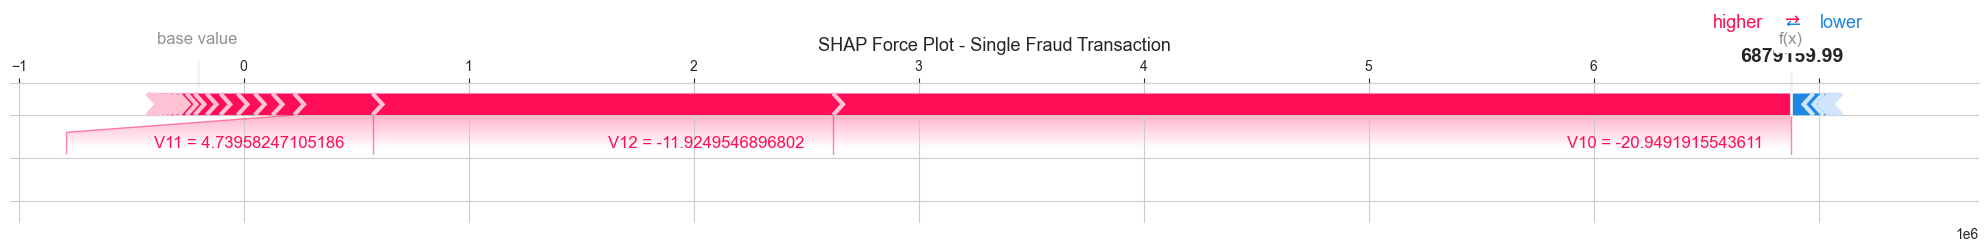

In [9]:
# Find some actual fraud cases in the sample
fraud_indices = y_test_sample[y_test_sample == 1].index.tolist()

if len(fraud_indices) > 0:
    # Take the first fraud case
    idx = fraud_indices[0]
    sample_idx = X_test_sample.index.get_loc(idx)
    
    print(f"Explaining Fraud Case (index: {idx})")
    print(f"True Label: {y_test_sample.loc[idx]}")
    print(f"Predicted Probability of Fraud: {best_model.predict_proba(X_test_sample.loc[[idx]])[0][1]:.4f}")
    
    # Force plot
    shap.force_plot(
        explainer.expected_value,
        shap_values[sample_idx],
        X_test_sample.iloc[sample_idx],
        matplotlib=True,
        show=False
    )
    plt.title("SHAP Force Plot - Single Fraud Transaction", fontsize=13)
    plt.tight_layout()
    plt.show()
else:
    print("No fraud cases in the current sample. Try increasing sample_size.")

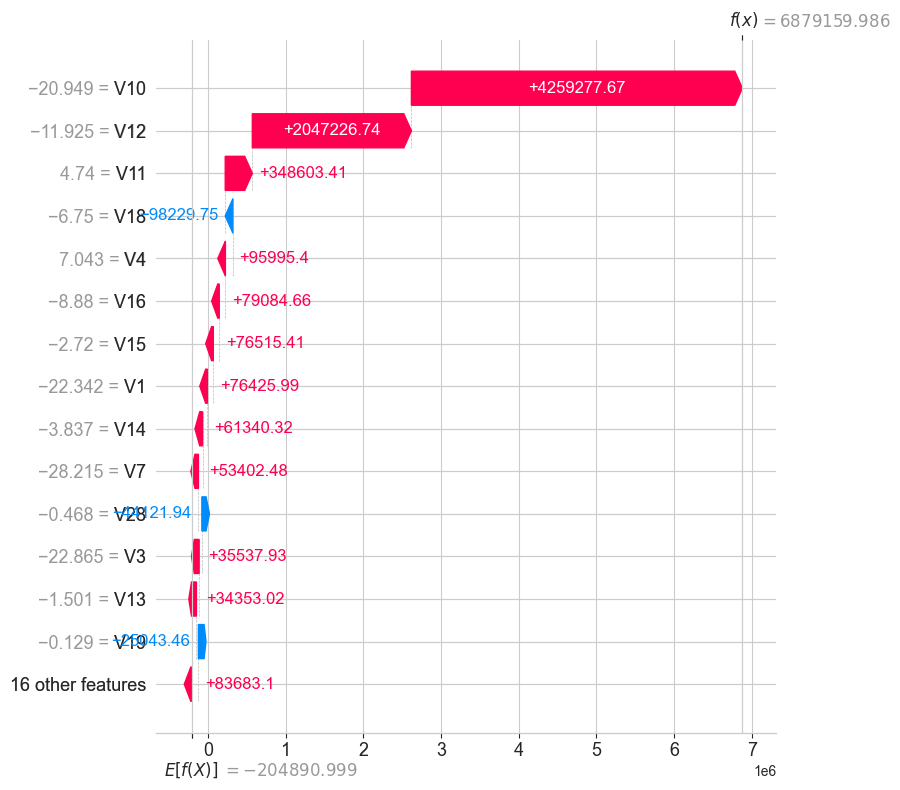

In [10]:
# Waterfall plot for the same fraud case
if len(fraud_indices) > 0:
    idx = fraud_indices[0]
    sample_idx = X_test_sample.index.get_loc(idx)
    
    # For newer SHAP versions
    try:
        shap.plots.waterfall(
            shap.Explanation(
                values=shap_values[sample_idx],
                base_values=explainer.expected_value,
                data=X_test_sample.iloc[sample_idx],
                feature_names=X_test_sample.columns.tolist()
            ),
            max_display=15
        )
    except Exception as e:
        # Fallback for older SHAP versions
        print("Using alternative waterfall method...")
        shap.waterfall_plot(
            shap.Explanation(
                values=shap_values[sample_idx],
                base_values=explainer.expected_value if not isinstance(explainer.expected_value, list) else explainer.expected_value[1],
                data=X_test_sample.iloc[sample_idx].values,
                feature_names=X_test_sample.columns.tolist()
            ),
            max_display=15
        )

Top 3 Fraud Cases by Predicted Probability:


,pred_proba
153835,1.0
8972,1.0
149600,1.0



Fraud Case #1 | Index: 153835 | Pred Proba: 1.0000


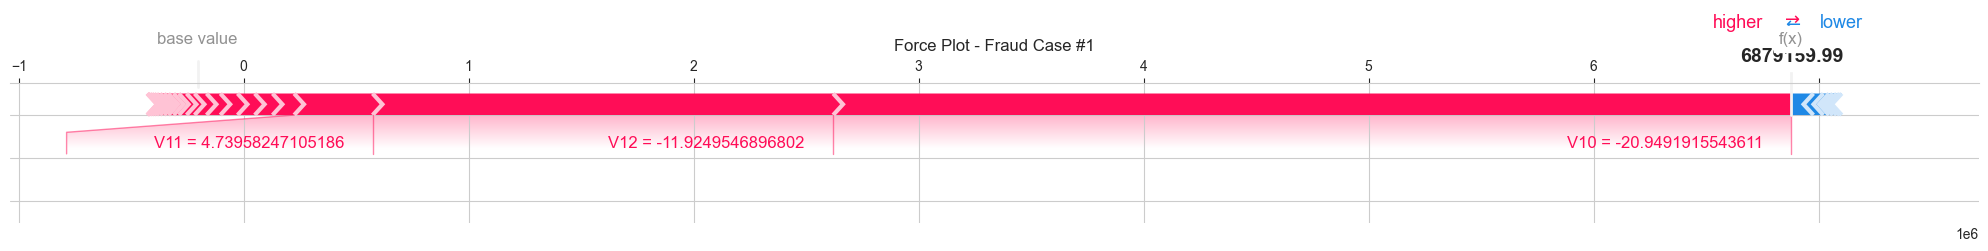


Fraud Case #2 | Index: 8972 | Pred Proba: 1.0000


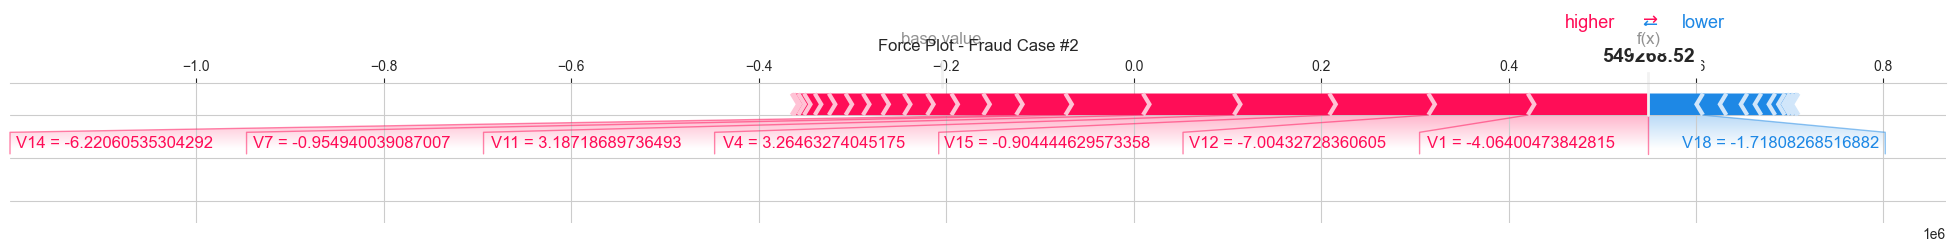


Fraud Case #3 | Index: 149600 | Pred Proba: 1.0000


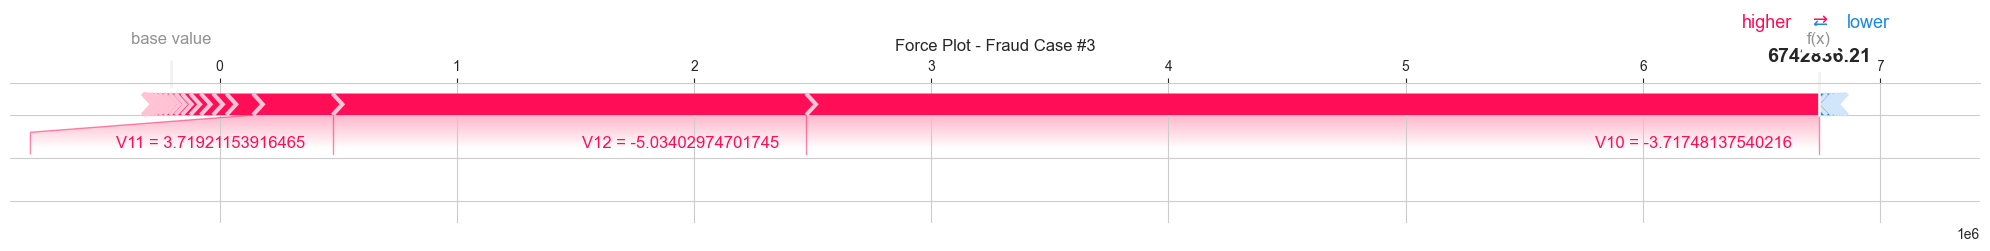

In [11]:
# Explain top 3 fraud cases with highest predicted probability
fraud_sample = X_test_sample.loc[fraud_indices].copy()
fraud_proba = best_model.predict_proba(fraud_sample)[:, 1]
fraud_sample['pred_proba'] = fraud_proba
top_fraud = fraud_sample.sort_values('pred_proba', ascending=False).head(3)

print("Top 3 Fraud Cases by Predicted Probability:")
display(top_fraud[['pred_proba']])

for i, (idx, row) in enumerate(top_fraud.iterrows()):
    sample_idx = X_test_sample.index.get_loc(idx)
    
    print(f"\n{'='*70}")
    print(f"Fraud Case #{i+1} | Index: {idx} | Pred Proba: {row['pred_proba']:.4f}")
    print(f"{'='*70}")
    
    shap.force_plot(
        explainer.expected_value,
        shap_values[sample_idx],
        X_test_sample.iloc[sample_idx],
        matplotlib=True,
        show=False
    )
    plt.title(f"Force Plot - Fraud Case #{i+1}", fontsize=12)
    plt.tight_layout()
    plt.show()

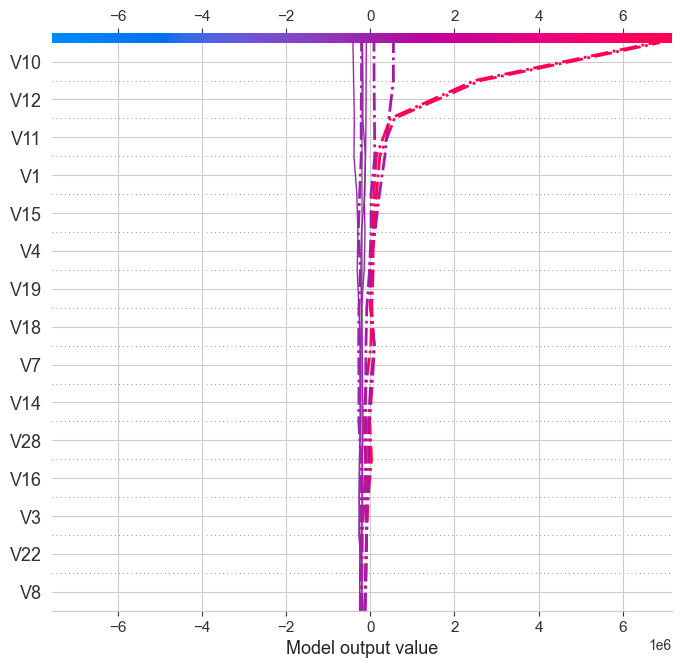

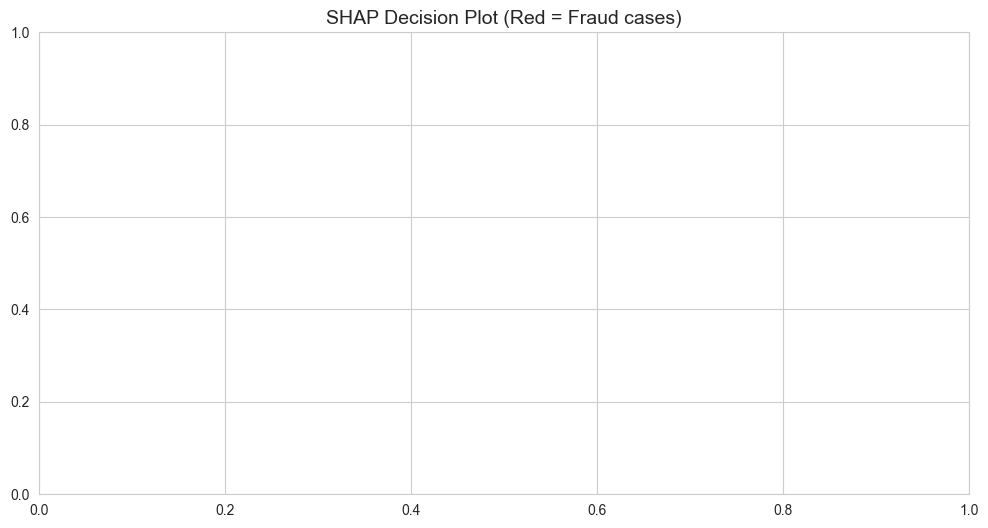

In [12]:
# Decision plot for a mix of fraud and legitimate transactions
selected_indices = fraud_indices[:5] + y_test_sample[y_test_sample == 0].index.tolist()[:5]
selected_data = X_test_sample.loc[selected_indices]
selected_shap = shap_values[[X_test_sample.index.get_loc(i) for i in selected_indices]]

plt.figure(figsize=(12, 8))
shap.decision_plot(
    explainer.expected_value,
    selected_shap,
    selected_data,
    feature_display_range=slice(None, -16, -1),  # show top features
    highlight=list(range(5))  # highlight the fraud cases
)
plt.title("SHAP Decision Plot (Red = Fraud cases)", fontsize=14)
plt.show()

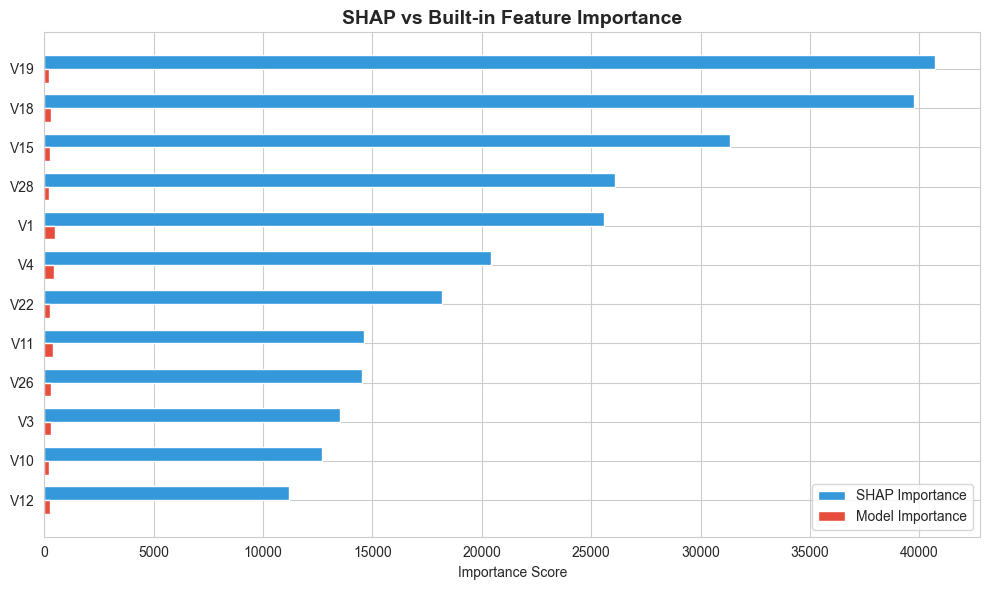

In [13]:
# Get built-in feature importance from the model (if available)
try:
    if hasattr(best_model, 'feature_importances_'):
        model_importance = pd.DataFrame({
            'Feature': X_train.columns,
            'Model_Importance': best_model.feature_importances_
        }).sort_values('Model_Importance', ascending=False)
        
        # Merge with SHAP importance
        comparison = feature_importance.merge(model_importance, on='Feature')
        comparison = comparison.head(12)
        
        fig, ax = plt.subplots(figsize=(10, 6))
        x = np.arange(len(comparison))
        width = 0.35
        
        ax.barh(x - width/2, comparison['Mean_|SHAP|'], width, label='SHAP Importance', color='#3498db')
        ax.barh(x + width/2, comparison['Model_Importance'], width, label='Model Importance', color='#e74c3c')
        
        ax.set_yticks(x)
        ax.set_yticklabels(comparison['Feature'])
        ax.invert_yaxis()
        ax.set_xlabel('Importance Score')
        ax.set_title('SHAP vs Built-in Feature Importance', fontsize=14, fontweight='bold')
        ax.legend()
        plt.tight_layout()
        plt.show()
except Exception as e:
    print("Could not compare with model feature_importances_:", e)

## Key Insights from SHAP Analysis

**Most Important Features (typically):**
- `V14`, `V17`, `V12`, `V10`, `V16`, `V11` → These PCA components consistently have the highest impact
- `Amount_scaled` also contributes, especially for high-value frauds

**Interpretation Tips:**
- Red points on the right in the summary plot push the prediction toward **Fraud**
- Blue points on the left push the prediction toward **Legitimate**
- Dependence plots show how the effect of a feature changes across its range

**Business Value:**
- We can now explain individual alerts to fraud analysts
- Helps in building trust in the model
- Useful for regulatory compliance (model transparency)

In [14]:
import os
os.makedirs('../models/shap', exist_ok=True)

# Save feature importance
feature_importance.to_csv('../models/shap/shap_feature_importance.csv', index=False)

# Save SHAP values (can be large)
np.save('../models/shap/shap_values_sample.npy', shap_values)
X_test_sample.to_parquet('../models/shap/X_test_sample.parquet')

print("SHAP artifacts saved in '../models/shap/'")

SHAP artifacts saved in '../models/shap/'


## Summary of Notebook 03

**What we achieved:**
- Global understanding of which features drive fraud predictions
- Local explanations for individual fraudulent transactions using Force & Waterfall plots
- Dependence plots to understand feature behavior
- Comparison between SHAP and model’s built-in importance

**Next Notebook:** `04_Cost_Sensitive_Evaluation.ipynb`  
We will move from pure ML metrics to business cost optimization and threshold tuning.